# DS 2003 Project 2: How NFL Teams Make Play-Calling Decisions
Group 7: Kamal Sangameswaran, Nahom Bezabhe, Parks Allred, Spencer

This notebook investigates how down and distance, score and time, and fourth-down situations relate to play selection in the 2025 NFL regular season. It generates charts and a short narrative plan for the November 15 check-in.

Run all cells from top to bottom. The first run needs internet access to download the official nflverse release, or a local copy of `play_by_play_2025.csv` or `play_by_play_2025.csv.gz`. Download the compressed file from [the official 2025 nflverse release](https://github.com/nflverse/nflverse-data/releases/download/pbp/play_by_play_2025.csv.gz) if you prefer to load it manually. Once downloaded, the local file is reused. No other data or custom modules are needed. The source CSV is large, so the notebook reads only the required columns.

The plots describe observed choices, not what coaches should do or evidence that any play call causes a win.

## 1. Imports and settings

Keep common choices here so the rest of the notebook can be rerun without changing individual charts.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

DATA_URL = "https://github.com/nflverse/nflverse-data/releases/download/pbp/play_by_play_2025.csv.gz"
DATA_FOLDER = Path(".")
OUTPUT_FOLDER = Path("nfl_narrative_figures")
OUTPUT_FOLDER.mkdir(exist_ok=True)

# Change these to compare two other teams
TEAM_A = "PHI"
TEAM_B = "KC"
MIN_TEAM_FOURTH_DOWNS = 20

plt.rcParams.update({"figure.figsize": (9, 5.5), "figure.dpi": 115,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11})
print("Charts will be saved in:", OUTPUT_FOLDER.resolve())

Charts will be saved in: /Users/kamal/DS2003Project2/DS2003-Project2Notebook/nfl_narrative_figures


## 2. Load the real data

This notebook points to the official [nflverse play-by-play release](https://github.com/nflverse/nflverse-data/releases/tag/pbp), specifically `play_by_play_2025.csv.gz`. The file is about 18 MB compressed. It first looks for a local CSV or CSV.gz in the notebook folder, then downloads and caches the official compressed file if necessary. No API key or extra Python module is needed. If the network blocks GitHub, manually download the file through the release page and put it next to this notebook.

Note: The dataset is not embedded in this notebook. Chart outputs and findings will appear after running it with the authentic data.

In [2]:
COLUMNS = ["season_type", "game_id", "posteam", "defteam", "play_type",
           "down", "ydstogo", "score_differential", "game_seconds_remaining",
           "week", "qtr"]

def load_play_data(folder=DATA_FOLDER):
    """Load selected NFL columns from a local file or official release."""
    csv_file = folder / "play_by_play_2025.csv"
    gzip_file = folder / "play_by_play_2025.csv.gz"

    if csv_file.exists():
        source = csv_file
    elif gzip_file.exists():
        source = gzip_file
    else:
        from urllib.request import urlopen
        temporary_file = folder / "play_by_play_2025.csv.gz.part"
        try:
            # Save in chunks and rename only after the download finishes
            with urlopen(DATA_URL, timeout=60) as response, temporary_file.open("wb") as output:
                while True:
                    chunk = response.read(1024 * 1024)
                    if not chunk:
                        break
                    output.write(chunk)
            temporary_file.replace(gzip_file)
        except Exception as error:
            temporary_file.unlink(missing_ok=True)
            raise RuntimeError(
                "Could not download the official nflverse release. Download "
                "play_by_play_2025.csv.gz from the release page and put it "
                f"next to this notebook. Details: {error}"
            ) from error
        source = gzip_file

    try:
        data = pd.read_csv(source, usecols=COLUMNS, low_memory=False)
    except Exception as error:
        raise RuntimeError(
            "The file could not be read. Make sure it is the 2025 nflverse "
            f"play-by-play CSV or CSV.gz. Details: {error}"
        ) from error
    return data, str(source)

raw, source = load_play_data()
print(f"Source: {source}")
print(f"Original data: {len(raw):,} rows, {len(raw.columns)} selected columns")
display(raw.head(3))

Source: play_by_play_2025.csv.gz
Original data: 48,771 rows, 11 selected columns


,game_id,season_type,week,posteam,defteam,game_seconds_remaining,qtr,down,ydstogo,play_type,score_differential
0,2025_01_ARI_NO,REG,1,NaN,NaN,3600.0,1,NaN,0,NaN,NaN
1,2025_01_ARI_NO,REG,1,ARI,NO,3600.0,1,NaN,0,kickoff,0.0
2,2025_01_ARI_NO,REG,1,ARI,NO,3596.0,1,1.0,10,run,0.0


## 3. Clean and prepare the plays

The proposal discusses the regular season, so playoff plays are excluded. For pass-rate analysis we keep only normal `run` and `pass` records, rather than treating punts, field goals, spikes, and other events as runs. The fourth-down analysis uses a separate set of four choices: run, pass, punt, and field goal.

A scramble can be coded as a run even on a designed pass. We measure nflverse's recorded play type, not the original offensive intent.

In [3]:
def prepare_plays(data):
    """Filter the season and prepare variables shared by the charts."""
    regular = data.loc[data["season_type"] == "REG"].copy()
    numeric_columns = ["down", "ydstogo", "score_differential", "game_seconds_remaining"]
    for column in numeric_columns:
        regular[column] = pd.to_numeric(regular[column], errors="coerce")

    regular = regular.dropna(subset=["posteam", "down", "ydstogo"])
    regular = regular[(regular["down"].between(1, 4)) & (regular["ydstogo"] >= 0)]
    regular["distance_group"] = pd.cut(
        regular["ydstogo"], bins=[-0.01, 2, 6, 10, np.inf],
        labels=["0-2 yards", "3-6 yards", "7-10 yards", "11+ yards"]
    )
    regular["score_group"] = pd.cut(
        regular["score_differential"], bins=[-np.inf, -9, -1, 0, 8, np.inf],
        labels=["Down 9+", "Down 1-8", "Tied", "Up 1-8", "Up 9+"]
    )
    # Time left in regulation; overtime is not included in the time chart
    regular["minutes_left"] = regular["game_seconds_remaining"] / 60
    regular["time_group"] = pd.cut(
        regular["minutes_left"], bins=[-0.01, 5, 15, 30, 60],
        labels=["0-5 min", "5-15 min", "15-30 min", "30-60 min"],
        include_lowest=True
    )
    return regular

def get_run_pass_plays(regular):
    """Return offensive runs and passes, with a simple pass indicator."""
    plays = regular.loc[regular["play_type"].isin(["run", "pass"])].copy()
    plays["is_pass"] = (plays["play_type"] == "pass").astype(int)
    return plays

def get_fourth_down_choices(regular):
    """Identify fourth-down play decisions, counting runs and passes as attempts."""
    fourth = regular.loc[
        (regular["down"] == 4) &
        (regular["play_type"].isin(["run", "pass", "punt", "field_goal"]))
    ].copy()
    fourth["go_for_it"] = fourth["play_type"].isin(["run", "pass"]).astype(int)
    return fourth

regular = prepare_plays(raw)
plays = get_run_pass_plays(regular)
fourth = get_fourth_down_choices(regular)

print(f"Regular-season rows after basic cleaning: {len(regular):,}")
print(f"Games: {regular['game_id'].nunique():,}")
print(f"Run/pass plays: {len(plays):,}")
print(f"Fourth-down decisions in selected categories: {len(fourth):,}")
print(f"Overall pass rate: {plays['is_pass'].mean():.1%}")

assert not plays.empty, "No valid runs or passes found"
assert not fourth.empty, "No fourth-down decisions found"
assert plays["play_type"].isin(["run", "pass"]).all()

Regular-season rows after basic cleaning: 38,841
Games: 272
Run/pass plays: 32,813
Fourth-down decisions in selected categories: 3,793
Overall pass rate: 56.8%


## 4. Finding candidate 1: Down and distance

Question: When do teams pass more often? This chart compares the pass rate across downs and distance-to-go groups. Each cell also shows how many plays it contains.

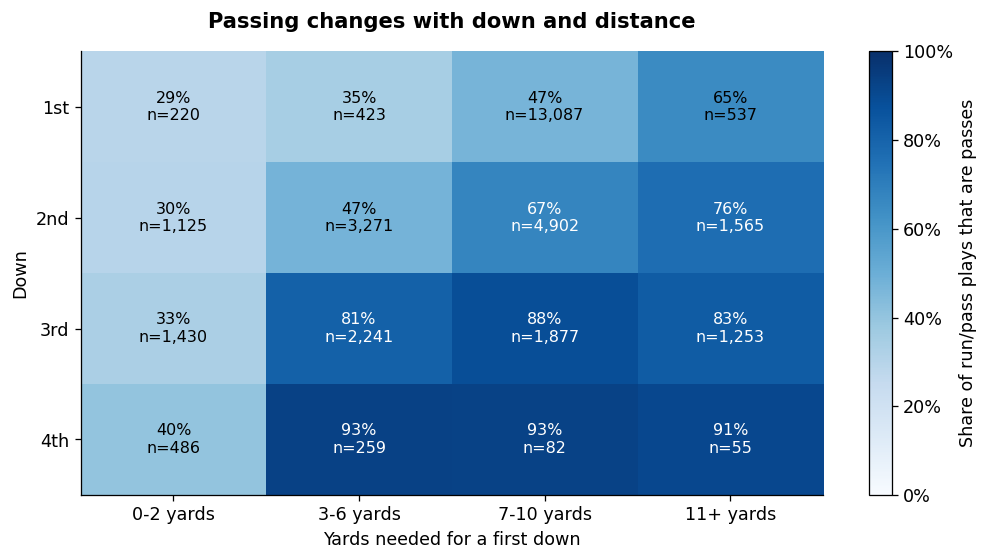

In [4]:
def summarize_down_distance(plays):
    return plays.pivot_table(index="down", columns="distance_group", values="is_pass",
                             aggfunc=["mean", "count"], observed=False)

def plot_down_distance(plays, save=True):
    summary = summarize_down_distance(plays)
    rates = summary["mean"].reindex(index=[1, 2, 3, 4])
    counts = summary["count"].reindex(index=[1, 2, 3, 4])
    fig, ax = plt.subplots(figsize=(9, 5))
    image = ax.imshow(rates.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for row in range(len(rates)):
        for column in range(len(rates.columns)):
            rate, count = rates.iloc[row, column], counts.iloc[row, column]
            label = f"{rate:.0%}\nn={int(count):,}" if pd.notna(rate) else "No plays"
            ax.text(column, row, label, ha="center", va="center",
                    color="white" if pd.notna(rate) and rate > 0.65 else "black", fontsize=10)
    ax.set_xticks(range(len(rates.columns)), [str(x) for x in rates.columns])
    ax.set_yticks(range(4), [f"{down}st" if down == 1 else f"{down}nd" if down == 2 else f"{down}rd" if down == 3 else "4th" for down in rates.index])
    ax.set_xlabel("Yards needed for a first down")
    ax.set_ylabel("Down")
    ax.set_title("Passing changes with down and distance", weight="semibold", pad=15)
    fig.colorbar(image, ax=ax, format=PercentFormatter(1), label="Share of run/pass plays that are passes")
    fig.tight_layout()
    if save:
        fig.savefig(OUTPUT_FOLDER / "01_down_distance.png", bbox_inches="tight")
    plt.show()
    return summary

down_summary = plot_down_distance(plays)

## 5. Finding candidate 2: Score and time

Question: Do teams change their run/pass balance when they are behind or ahead? The chart separates late-game plays from earlier plays and compares the score situation. Sparse groups are labeled with sample sizes.

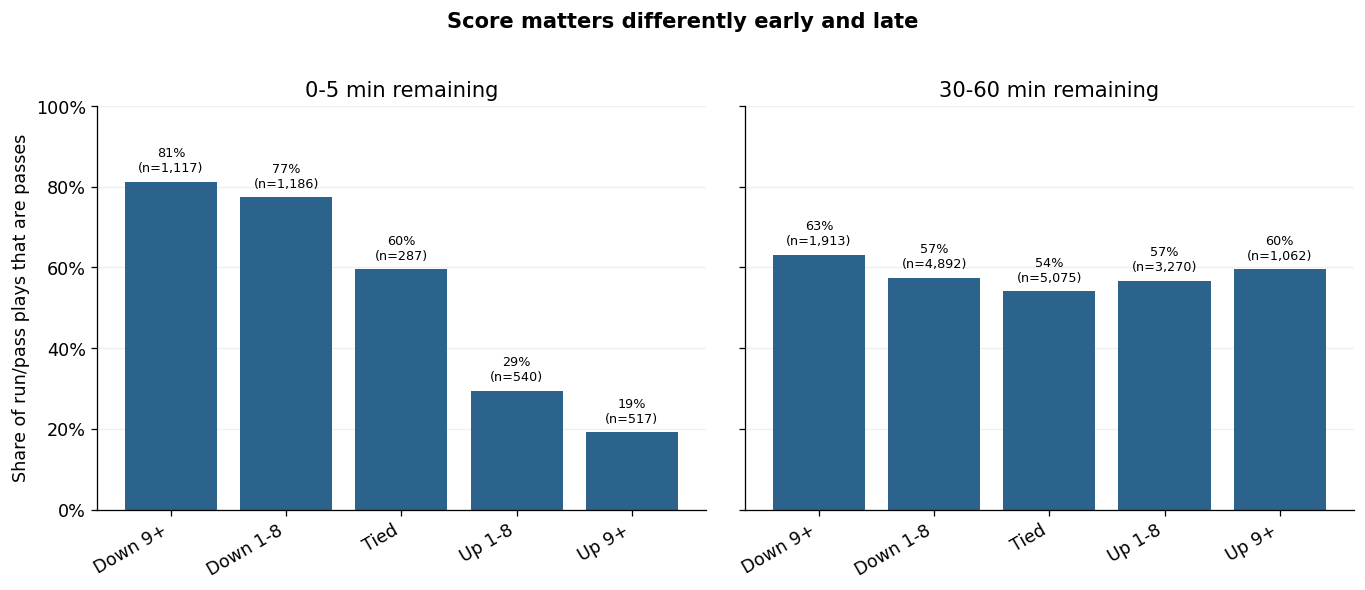

In [5]:
def summarize_score_time(plays):
    subset = plays.dropna(subset=["score_group", "time_group"])
    grouped = subset.groupby(["time_group", "score_group"], observed=False)["is_pass"]
    return grouped.agg(["mean", "size"]).reset_index()

def plot_score_time(plays, save=True):
    summary = summarize_score_time(plays)
    scores = ["Down 9+", "Down 1-8", "Tied", "Up 1-8", "Up 9+"]
    times = ["0-5 min", "5-15 min", "15-30 min", "30-60 min"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
    for ax, time_label in zip(axes, ["0-5 min", "30-60 min"]):
        subset = summary.loc[summary["time_group"] == time_label].set_index("score_group")
        subset = subset.reindex(scores)
        bars = ax.bar(range(len(scores)), subset["mean"], color="#2c638c")
        ax.set_xticks(range(len(scores)), scores, rotation=30, ha="right")
        ax.set_ylim(0, 1)
        ax.set_title(f"{time_label} remaining")
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)
        for bar, (_, row) in zip(bars, subset.iterrows()):
            if pd.notna(row["mean"]):
                ax.text(bar.get_x() + bar.get_width() / 2, row["mean"] + 0.025,
                        f"{row['mean']:.0%}\n(n={int(row['size']):,})",
                        ha="center", fontsize=8)
    axes[0].set_ylabel("Share of run/pass plays that are passes")
    axes[0].yaxis.set_major_formatter(PercentFormatter(1))
    fig.suptitle("Score matters differently early and late", weight="semibold", y=1.02)
    fig.tight_layout()
    if save:
        fig.savefig(OUTPUT_FOLDER / "02_score_and_time.png", bbox_inches="tight")
    plt.show()
    return summary

score_time_summary = plot_score_time(plays)

## 6. Finding candidate 3: Fourth-down aggression

Question: Which teams go for it most on fourth down? We compare attempts (run/pass) with other fourth-down decisions (punt/field goal). This is a descriptive comparison, not a ranking of coaching quality. Teams face different field positions, scores, and distances.

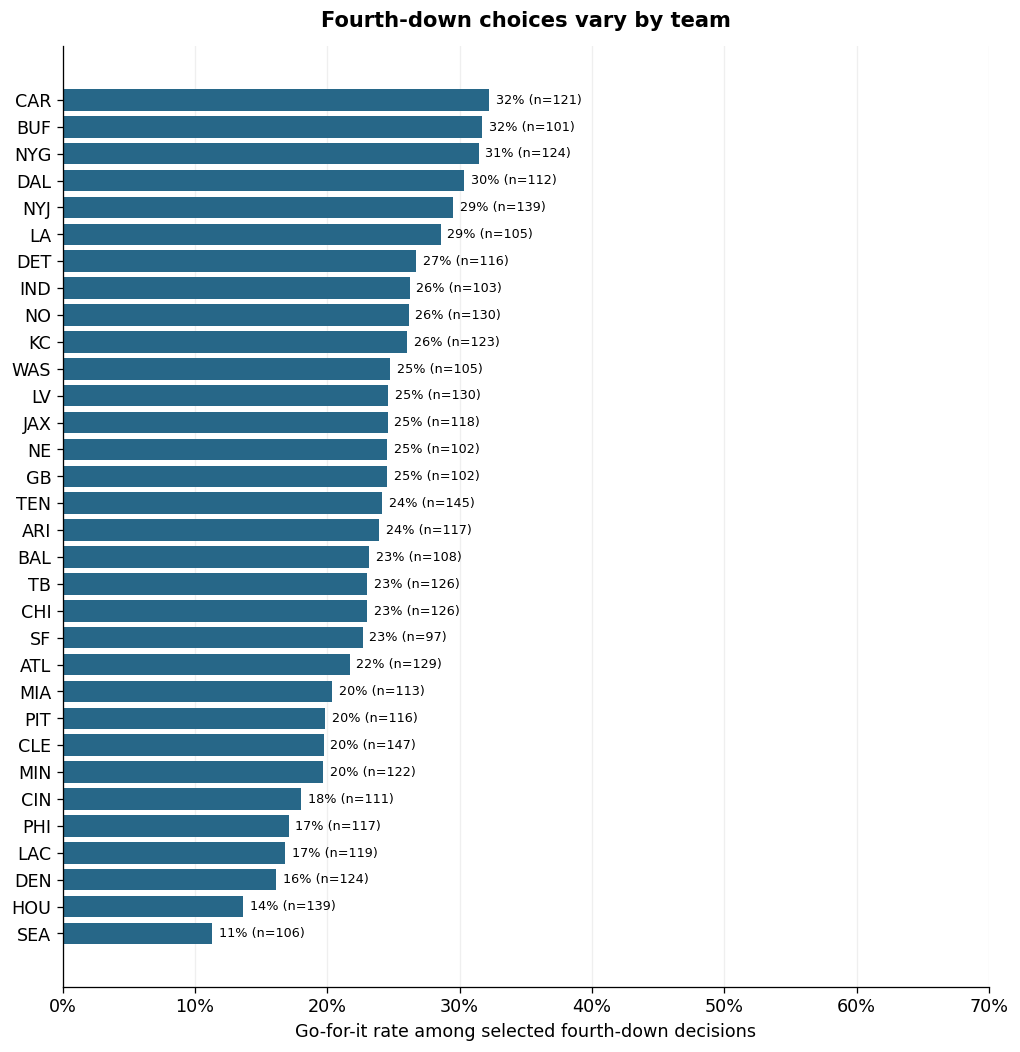

,posteam,go_rate,decisions,attempts
4,CAR,0.322314,121,39
3,BUF,0.316832,101,32
23,NYG,0.314516,124,39
8,DAL,0.303571,112,34
24,NYJ,0.294964,139,41
16,LA,0.285714,105,30
10,DET,0.267241,116,31
13,IND,0.262136,103,27
22,NO,0.261538,130,34
15,KC,0.260163,123,32


In [6]:
def summarize_fourth_down(fourth):
    return (fourth.groupby("posteam")["go_for_it"]
            .agg(go_rate="mean", decisions="size", attempts="sum")
            .reset_index().sort_values("go_rate", ascending=False))

def plot_fourth_down(fourth, minimum=MIN_TEAM_FOURTH_DOWNS, save=True):
    summary = summarize_fourth_down(fourth)
    shown = summary.loc[summary["decisions"] >= minimum].copy()
    if shown.empty:
        raise ValueError("Not enough fourth-down choices for the minimum sample threshold")
    shown = shown.sort_values("go_rate")
    fig, ax = plt.subplots(figsize=(9, max(6, 0.29 * len(shown))))
    bars = ax.barh(shown["posteam"], shown["go_rate"], color="#276788")
    for bar, (_, row) in zip(bars, shown.iterrows()):
        ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height() / 2,
                f"{row['go_rate']:.0%} (n={int(row['decisions'])})", va="center", fontsize=8)
    ax.set_xlim(0, max(0.7, shown["go_rate"].max() + 0.17))
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlabel("Go-for-it rate among selected fourth-down decisions")
    ax.set_title("Fourth-down choices vary by team", weight="semibold", pad=12)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    fig.tight_layout()
    if save:
        fig.savefig(OUTPUT_FOLDER / "03_fourth_down_teams.png", bbox_inches="tight")
    plt.show()
    return summary

fourth_summary = plot_fourth_down(fourth)
display(fourth_summary.head(10))

## 7. Optional team comparison

This is a simple notebook-based version of the team comparison described in the proposal. Change `TEAM_A` and `TEAM_B` in the settings cell to compare two teams on each down. It is intentionally basic so that an interactive version can be added later.

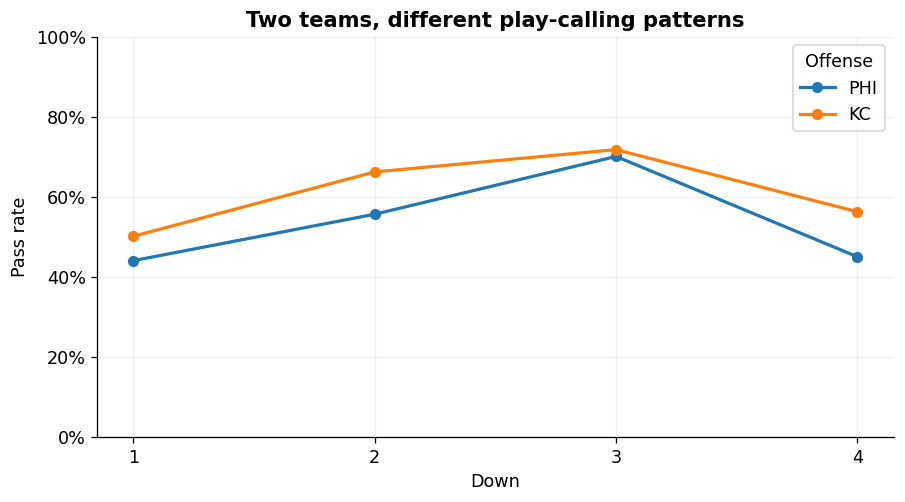

In [7]:
def compare_teams(plays, team_a, team_b, save=True):
    selected = plays.loc[plays["posteam"].isin([team_a, team_b])]
    result = selected.groupby(["posteam", "down"])["is_pass"].agg(["mean", "size"])
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for team in [team_a, team_b]:
        if team not in result.index.get_level_values(0):
            print(f"No run/pass plays for {team}; check the team abbreviation")
            continue
        row = result.loc[team].reindex([1, 2, 3, 4])
        ax.plot(row.index, row["mean"], marker="o", linewidth=2, label=team)
    ax.set_xticks([1, 2, 3, 4])
    ax.set_xlabel("Down")
    ax.set_ylabel("Pass rate")
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_title("Two teams, different play-calling patterns", weight="semibold")
    ax.legend(title="Offense")
    ax.grid(alpha=0.2)
    fig.tight_layout()
    if save:
        fig.savefig(OUTPUT_FOLDER / "04_team_comparison.png", bbox_inches="tight")
    plt.show()
    return result

team_comparison = compare_teams(plays, TEAM_A, TEAM_B)

## 8. Results and narrative decision

This section creates a short, data-based check-in draft from the computed results and identifies the exact chart files to attach. It favors the score-and-time story because it works well as an infographic progression, but the selected takeaway is generated using the observed values rather than assuming a result.

Review the wording and verify the figures before submitting. The exported PNGs are in `nfl_narrative_figures`.

In [8]:
def get_group_rate(summary, time_group, score_group):
    matches = summary.loc[(summary["time_group"] == time_group) &
                          (summary["score_group"] == score_group)]
    if len(matches) == 0 or pd.isna(matches.iloc[0]["mean"]):
        return None, 0
    return float(matches.iloc[0]["mean"]), int(matches.iloc[0]["size"])

def make_narrative_plan(plays, fourth_summary, score_time_summary):
    down_rates = plays.groupby("down")["is_pass"].mean()
    early_trail, early_trail_n = get_group_rate(score_time_summary, "30-60 min", "Down 9+")
    early_lead, early_lead_n = get_group_rate(score_time_summary, "30-60 min", "Up 9+")
    late_trail, late_trail_n = get_group_rate(score_time_summary, "0-5 min", "Down 9+")
    late_lead, late_lead_n = get_group_rate(score_time_summary, "0-5 min", "Up 9+")
    strongest = fourth_summary.iloc[0]
    weakest = fourth_summary.iloc[-1]

    def rate(value):
        return f"{value:.0%}" if value is not None else "not available"

    if late_trail is not None and late_lead is not None:
        main_point = (f"In the final five minutes, teams trailing by at least nine points passed on "
                      f"{rate(late_trail)} of run/pass plays, versus {rate(late_lead)} "
                      "for teams leading by at least nine points.")
    else:
        main_point = "NFL play selection changes with the score and how much time remains."

    result = f"""# Narrative Structure Check-in | Group 7

## Candidate findings and chart evidence
1. Down and distance: Pass rates range from {down_rates.min():.0%} to {down_rates.max():.0%} across downs when combined over distance. Chart: `01_down_distance.png` (rates by both down and distance).
2. Score and time: With 0-5 minutes remaining, pass rates are {rate(late_trail)} when down 9+ (n={late_trail_n:,}) and {rate(late_lead)} when up 9+ (n={late_lead_n:,}). Chart: `02_score_and_time.png`.
3. Fourth-down decisions: {strongest['posteam']} goes for it on {strongest['go_rate']:.0%} of its included decisions (n={int(strongest['decisions'])}), while {weakest['posteam']} is at {weakest['go_rate']:.0%} (n={int(weakest['decisions'])}). Chart: `03_fourth_down_teams.png`. These are unadjusted rates.

## Decision
Main takeaway: {main_point}
Track: Infographic. Audience: NFL fans and casual sports viewers. We chose score and time because the early-versus-late comparison tells a clear story without requiring readers to understand complicated football statistics. Down-and-distance and team aggressiveness are useful context, but harder to explain in one main message.

## Narrative structure and beat-by-beat outline
Structure: Partitioned poster with three panels and short annotations. It fits an infographic because readers can follow the evidence in order or scan each panel separately.
1. Hook: "Why do NFL teams change their play calls late in games?" Define pass rate and show a brief early-game comparison from chart 2.
2. Evidence: Put the late-game comparison beside the early-game one, retaining the same score categories, axis scale, and sample labels. Annotate the largest supported difference.
3. Takeaway: State the main takeaway above in a short closing sentence, with a note that these are observed choices, not proof that passing causes better outcomes.

## Chart plan
Reuse `02_score_and_time.png` as the core evidence, redesigning it into two large, consistently scaled static panels with direct labels. Use a simplified portion of `01_down_distance.png` as an optional small context chart. Keep `03_fourth_down_teams.png` as an alternate story or appendix, not the centerpiece. No new analysis is required for the check-in; a later infographic could add a final-five-minutes score-difference callout.

Source: nflverse 2025 play-by-play, regular-season plays, restricted to recorded runs and passes for pass-rate charts. Fourth-down chart uses run, pass, punt and field-goal decisions. Descriptive associations only.
"""
    return result

plan = make_narrative_plan(plays, fourth_summary, score_time_summary)
display(Markdown(plan))
(OUTPUT_FOLDER / "narrative_checkin_plan.md").write_text(plan, encoding="utf-8")
print("Saved plan and all four charts to:", OUTPUT_FOLDER.resolve())

# Narrative Structure Check-in | Group 7

## Candidate findings and chart evidence
1. Down and distance: Pass rates range from 47% to 73% across downs when combined over distance. Chart: `01_down_distance.png` (rates by both down and distance).
2. Score and time: With 0-5 minutes remaining, pass rates are 81% when down 9+ (n=1,117) and 19% when up 9+ (n=517). Chart: `02_score_and_time.png`.
3. Fourth-down decisions: CAR goes for it on 32% of its included decisions (n=121), while SEA is at 11% (n=106). Chart: `03_fourth_down_teams.png`. These are unadjusted rates.

## Decision
Main takeaway: In the final five minutes, teams trailing by at least nine points passed on 81% of run/pass plays, versus 19% for teams leading by at least nine points.
Track: Infographic. Audience: NFL fans and casual sports viewers. We chose score and time because the early-versus-late comparison tells a clear story without requiring readers to understand complicated football statistics. Down-and-distance and team aggressiveness are useful context, but harder to explain in one main message.

## Narrative structure and beat-by-beat outline
Structure: Partitioned poster with three panels and short annotations. It fits an infographic because readers can follow the evidence in order or scan each panel separately.
1. Hook: "Why do NFL teams change their play calls late in games?" Define pass rate and show a brief early-game comparison from chart 2.
2. Evidence: Put the late-game comparison beside the early-game one, retaining the same score categories, axis scale, and sample labels. Annotate the largest supported difference.
3. Takeaway: State the main takeaway above in a short closing sentence, with a note that these are observed choices, not proof that passing causes better outcomes.

## Chart plan
Reuse `02_score_and_time.png` as the core evidence, redesigning it into two large, consistently scaled static panels with direct labels. Use a simplified portion of `01_down_distance.png` as an optional small context chart. Keep `03_fourth_down_teams.png` as an alternate story or appendix, not the centerpiece. No new analysis is required for the check-in; a later infographic could add a final-five-minutes score-difference callout.

Source: nflverse 2025 play-by-play, regular-season plays, restricted to recorded runs and passes for pass-rate charts. Fourth-down chart uses run, pass, punt and field-goal decisions. Descriptive associations only.


Saved plan and all four charts to: /Users/kamal/DS2003Project2/DS2003-Project2Notebook/nfl_narrative_figures


## 9. Source and interpretation notes

Data: [nflverse 2025 play-by-play release](https://github.com/nflverse/nflverse-data/releases/tag/pbp). The official file has many columns, but the code reads only the ones needed for this analysis.

- Percentages are play-level percentages, not percentages of teams or games
- The down-and-distance and score-and-time analyses count only plays coded as `run` or `pass`
- The fourth-down denominator is coded `run`, `pass`, `punt`, or `field_goal`, excluding penalties and other events; play type may not capture an aborted or fake attempt as expected
- Comparisons do not control for opponent, field position, team strength, or other confounding factors
- All figures and the written plan are created from the loaded data each time the notebook runs

Use the three exported candidate chart PNGs in the submission alongside the generated one-page draft. If the generated text is too long in your document editor, compress the figure explanations first.